# 02 · Nick Saim Mayta Jara — Conexiones (flujos)

**Pregunta central del proyecto:** ¿cómo detectar a tiempo comportamientos
anómalos en el tráfico de red del laboratorio para que la mesa de TI reaccione
antes de que se conviertan en incidentes?

**Mi dimensión:** ¿cuántas conexiones se abren, hacia qué servicios, y se está
disparando la actividad?

| | U1 (batch, este notebook) | U2 (streaming, Grafana) |
|---|---|---|
| Indicador | flujos por hora / por servicio | flujos nuevos por minuto |
| Predicción | flujos de la próxima hora | flujos del minuto siguiente |
| Fuente | Data Lake Gold/Silver (TRCU.csv) | Kafka `trafico-flujos` → Spark |

In [1]:
import sys
sys.path.insert(0, "/jobs")
sys.path.insert(0, "/notebooks")

import matplotlib.pyplot as plt
from pyspark.sql import functions as F

from analisis_comun import cargar, metricas_streaming, modelo_horario, perfil_horario, picos, resumen
from comun import crear_spark

spark = crear_spark("nb-02-nick")
silver, gold = cargar(spark)
IND = "flujos"

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/30 00:50:48 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


## 1. Descriptivo

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


                     flujos
minutos        34751.000000
total         397354.000000
promedio_min      11.434318
mediana_min       10.000000
p99_min           46.000000
max_min          148.000000


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


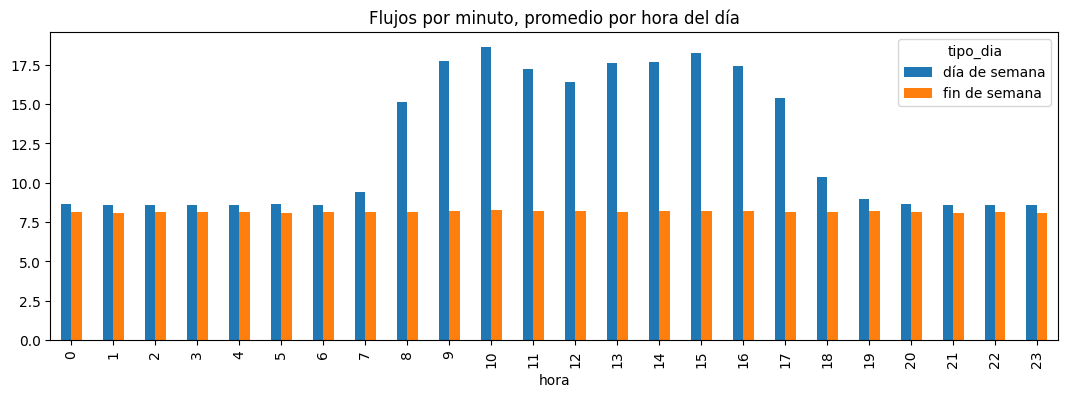

In [2]:
print(resumen(gold, IND).to_string())
perfil_horario(gold, IND).plot(kind="bar", figsize=(13, 4), title="Flujos por minuto, promedio por hora del día")
plt.show()

## 2. Diagnóstico: ¿hacia qué servicios y cómo son las conexiones?

In [3]:
servicios = (silver.withColumn("puerto", F.least("dport", "sport"))
             .groupBy("puerto", "ip_prot").count().orderBy(F.desc("count")).limit(12).toPandas())
servicios["protocolo"] = servicios["ip_prot"].map({6: "TCP", 17: "UDP", 1: "ICMP"}).fillna("otro")
print(servicios[["puerto", "protocolo", "count"]].to_string(index=False))

/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


 puerto protocolo  count
  10001       UDP 160602
  10002       UDP 105964
   5355       UDP  32672
   5353       UDP  25971
    443       TCP  17747
   8014       UDP   9539
    443       UDP   4888
  50160       UDP   4860
    137       UDP   4572
    138       UDP   3692
   9999       UDP   3272
  56700       UDP   3057


Duración de las conexiones: mediana 0.00 s | p90 60.00 s | p99 120.0 s


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


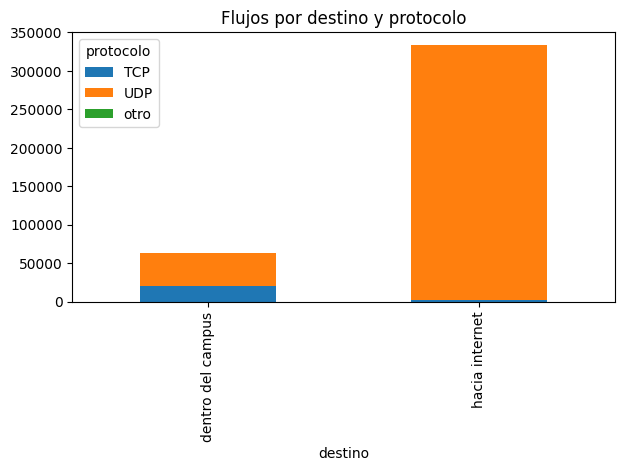

In [4]:
duracion = (silver.withColumn("duracion_s", F.col("duracion_us") / 1e6)
            .select(F.expr("percentile_approx(duracion_s, array(0.5, 0.9, 0.99))").alias("p")).first()["p"])
print(f"Duración de las conexiones: mediana {duracion[0]:.2f} s | p90 {duracion[1]:.2f} s | p99 {duracion[2]:.1f} s")

mezcla = silver.groupBy(F.when(F.col("dst_interna"), "dentro del campus").otherwise("hacia internet").alias("destino"),
                        F.when(F.col("ip_prot") == 6, "TCP").when(F.col("ip_prot") == 17, "UDP").otherwise("otro").alias("protocolo")
                        ).count().toPandas()
mezcla.pivot(index="destino", columns="protocolo", values="count").fillna(0).plot(
    kind="bar", stacked=True, figsize=(7, 3.5), title="Flujos por destino y protocolo")
plt.show()

In [5]:
print("Minutos con más conexiones de lo normal para su hora:")
print(picos(gold, IND).to_string(index=False))

Minutos con más conexiones de lo normal para su hora:


/usr/local/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


     ventana_inicio  flujos  media_de_esa_hora    z
2026-07-01 15:00:00     148               15.5 10.7
2026-08-13 16:33:00     131               14.8  9.9
2026-07-01 15:31:00     124               15.5  8.7
2026-08-11 18:04:00      54                9.7  8.5
2026-07-02 11:06:00     106               15.0  8.2
2026-07-02 11:07:00     105               15.0  8.1
2026-08-11 18:00:00      51                9.7  8.0
2026-07-02 08:41:00      97               12.9  7.8
2026-08-17 07:41:00      41                9.0  7.7
2026-07-02 08:37:00      95               12.9  7.6


## 3. Predictivo U1: flujos de la próxima hora (batch)

In [6]:
tabla, horas = modelo_horario(gold, IND)
print(f"{horas} horas consecutivas, división cronológica 80/20")
print(tabla.to_string())

26/10/30 00:51:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:51:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:10 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:11 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:51:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


...

26/10/30 00:51:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:24 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:25 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.


26/10/30 00:51:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 00:51:26 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/10/30 0

740 horas consecutivas, división cronológica 80/20
                      rmse      mae     r2  mejora_vs_persistencia_%
persistencia       208.987   94.730  0.486                     0.000
linear_regression  199.630  108.174  0.531                     4.477
random_forest      179.668   89.855  0.620                    14.029


## 4. U2: el modelo que corre en vivo (por minuto)

In [7]:
m, test, cv = metricas_streaming(IND)
print(f"Ganador: {m['ganador']} (escala {m['escala']}) | filas: {m['filas_total']:,}")
print(test.to_string())
print("\nBúsqueda de hiperparámetros (RMSE promedio de validación):")
print(cv.head(8).to_string(index=False))
print("\nVariables más importantes:", m["importancia_variables"])

Ganador: random_forest (escala original) | filas: 26,316
                     rmse    mae     r2  mejora_vs_persistencia_%
persistencia       10.324  6.759 -0.244                      0.00
linear_regression   6.671  3.612  0.480                     35.38
random_forest       5.600  2.929  0.634                     45.76
gbt                 6.291  3.389  0.538                     39.06

Búsqueda de hiperparámetros (RMSE promedio de validación):
       modelo   escala  regParam  rmse_cv  numTrees  maxDepth  maxIter
random_forest original       NaN    3.985      40.0      10.0      NaN
random_forest      log       NaN    4.220      40.0      10.0      NaN
random_forest original       NaN    4.254      40.0       6.0      NaN
          gbt original       NaN    4.265       NaN       5.0     50.0
          gbt original       NaN    4.298       NaN       3.0     50.0
random_forest      log       NaN    4.503      40.0       6.0      NaN
          gbt      log       NaN    4.542       NaN     

## 5. Conclusiones
- **La mayoría de los flujos no es navegación:** los puertos más frecuentes
  son anuncios y descubrimiento de la red local por UDP (10001/10002, LLMNR
  5355, mDNS 5353, NetBIOS 137/138). HTTPS (443/TCP) aparece recién en el
  quinto lugar con 17 747 flujos.
- **Duración:** la mediana es 0 s (flujos de un solo paquete, típicos de esos
  anuncios), el p90 60 s y el p99 120 s, que es el corte máximo del extractor.
- En promedio hay **11,4 flujos por minuto** (p99 = 46, máximo 148).
- **U1 (por hora):** el Random Forest mejora 14 % el RMSE frente a la persistencia.
- **U2 (por minuto):** es el indicador más predecible del proyecto (RF,
  +45,8 %, R² 0,63). Un salto de conexiones sin salto de bytes es la señal
  típica de escaneo o malware, por eso se cruza con SYN y con el K-Means.